## How to Use EvalxNLP Framework for Sentiment Analysis – A Beginner-Friendly Guide 🚀

#### What is EvalxNLP?

Imagine you have a sentiment analysis model that predicts whether a sentence is positive, neutral, or negative. But how does it know what makes a sentence negative? Does it focus on the right words?

That’s where EvalxNLP helps! 🦊

✅ EvalxNLP explains model predictions by showing which words had the most impact.

✅ Helps you trust the model’s decisions.

✅ Useful for debugging why your model makes mistakes.

In [1]:
import sys
sys.path.append('..')
from XAIbenchmark import XAIFramework
import warnings

warnings.filterwarnings("ignore")

d:\EvalNLP\venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
%load_ext autoreload
%autoreload 2

#### Single Sentence

Step 1: Load a pre-trained Sentiment Model, and Tokenizer

In [3]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer

model_name = "cardiffnlp/twitter-xlm-roberta-base-sentiment"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

Step 2: Optionally initialize the explainers, and evaluators

In [4]:
import torch
from explainers import InputXGradientExplainer, IntegratedGradientsExplainer, DeepLiftExplainer, LimeExplainer, SHAPExplainer, SHAPIQExplainer, GuidedBackpropExplainer
device = "cuda" if torch.cuda.is_available() else "cpu"
ig= IntegratedGradientsExplainer(model,tokenizer,device)
gb= GuidedBackpropExplainer(model,tokenizer,device)
dl= DeepLiftExplainer(model,tokenizer,device)
ixg= InputXGradientExplainer(model,tokenizer,device,multiply_by_inputs=True)
g= InputXGradientExplainer(model,tokenizer,device,multiply_by_inputs=False)
lime= LimeExplainer(model,tokenizer)
shap= SHAPExplainer(model,tokenizer)
shapiq= SHAPIQExplainer(model,tokenizer)

In [5]:
from evaluators import AUCTPEvaluator, SoftComprehensivenessEvaluator, SoftSufficiencyEvaluator, FADEvaluator, SparsenessEvaluator, ComplexityEvaluator, IOUF1Evaluator,TokenF1Evaluator, AUPRCEvaluator

sc= SoftComprehensivenessEvaluator(model,tokenizer,device)
ss= SoftSufficiencyEvaluator(model,tokenizer,device)
fad= FADEvaluator(model,tokenizer,device)
sp= SparsenessEvaluator(model,tokenizer,device)
cx= ComplexityEvaluator(model,tokenizer,device)
auctp= AUCTPEvaluator(model,tokenizer,device)
iou_f1= IOUF1Evaluator(model,tokenizer,device)
token_f1= TokenF1Evaluator(model,tokenizer,device)
auprc= AUPRCEvaluator(model,tokenizer,device)

Step 3: Inialize XAIBenchmark Class

In [6]:
xai_framework = XAIFramework(model, tokenizer,explainers=[gb,dl,ixg,g], evaluators=[sc,ss,iou_f1],device=device)

> **Note:** If you don’t pass any explainers or evaluators, it defaults to all explainers/evaluators.

Step 4: Predict Sentiment of a Sentence

In [7]:
#Define the senece to be explained
# sentence= "Great movie for a great nap!"
# sentence= "A masterpiece of how not to make a movie."
sentence= "Worst experience I've ever had!"
xai_framework.classify_text(sentence)

{'negative': 0.9348725080490112,
 'neutral': 0.04129568114876747,
 'positive': 0.0238318033516407}

Step 5: Use EvalxNLP to Explain Why

You can use the `XAIBenchmark` class to explain for all the explainers defined during the initiation of the `XAIBenchmark` class

In [8]:
exps= xai_framework.explain(input_data=sentence,target_label="negative")
exps

[Explanation(text=["Worst experience I've ever had!"], tokens=['<s>', '▁Wor', 'st', '▁experience', '▁I', "'", 've', '▁ever', '▁had', '!', '</s>'], scores=array([-0.06126126, -0.38918918, -0.1009009 ,  0.14414415, -0.00720721,
        -0.02162162,  0.02702703, -0.01441441, -0.01441441, -0.0036036 ,
        -0.21621622], dtype=float32), explainer='GBP', target_pos_idx=0, target_token_pos_idx=None, target='negative', target_token=None, rationale=None),
 Explanation(text=["Worst experience I've ever had!"], tokens=['<s>', '▁Wor', 'st', '▁experience', '▁I', "'", 've', '▁ever', '▁had', '!', '</s>'], scores=array([ 0.        , -0.5617887 ,  0.09627717,  0.01015818, -0.1000091 ,
         0.02188067,  0.00167619, -0.04051486,  0.0380265 ,  0.12966855,
         0.        ], dtype=float32), explainer='DL', target_pos_idx=0, target_token_pos_idx=None, target='negative', target_token=None, rationale=None),
 Explanation(
   text=["Worst experience I've ever had!"],
   tokens=['<s>', '▁Wor', 'st', '▁

Or you can use an individual explainer's `compute_feature_importance` method to get importance scores.

In [9]:
# ig_exps= ig.compute_feature_importance(sentence, target="positive")
# gb_exps= gb.compute_feature_importance(sentence, target="positive")
# dl_exps= dl.compute_feature_importance(sentence, target="positive")
# ixg_exps= ixg.compute_feature_importance(sentence, target="positive")
# lime_exps= lime.compute_feature_importance(sentence, target="positive")
# shap_exps= shap.compute_feature_importance(sentence, target="positive")
# shapiq_exps= shapiq.compute_feature_importance(sentence, target="positive")
# g_exps= g.compute_feature_importance(sentence, target="positive")

Step 5: Visualize the Explanation

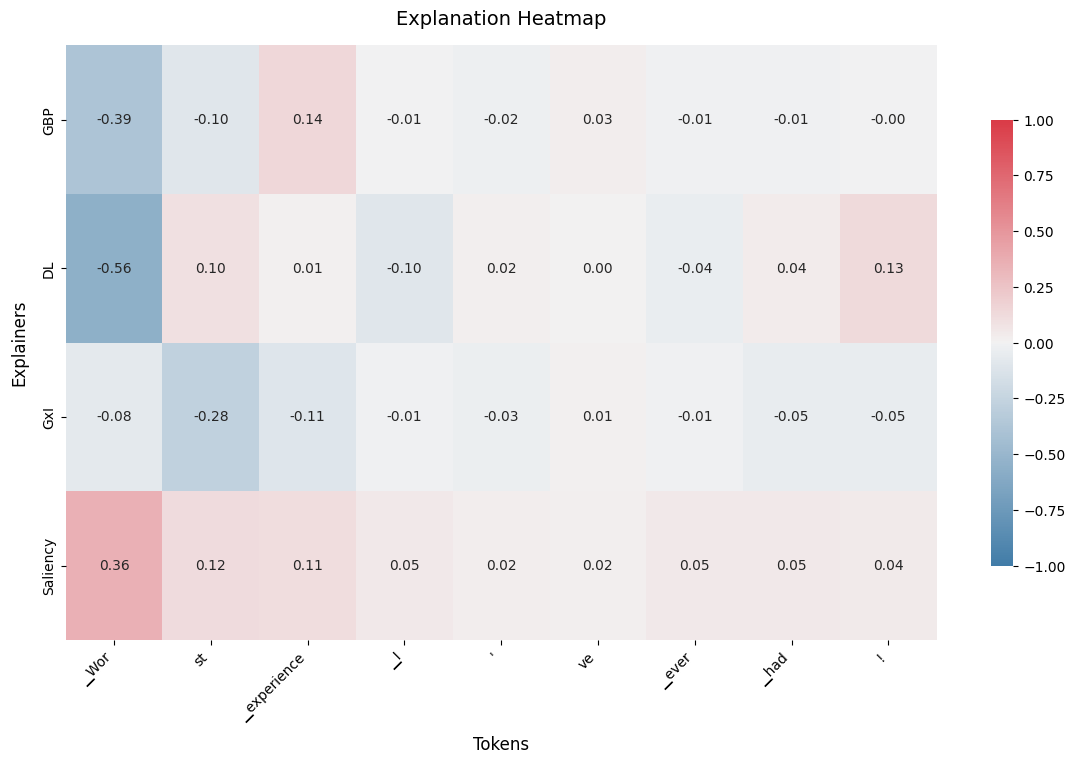

In [10]:
xai_framework.visualize(exps)

Step 6: Interpret and understand scores by LLM generated textual explanations

In [11]:
from LLMExplanationGenerator import LLMExplanationGenerator
import pandas as pd
from IPython.display import display, HTML

api_key = "9b305c0291728a7f4ca861254b9bedd3e7785d5360100d93603dd1758931be6d"
explainer = LLMExplanationGenerator(api_key=api_key)

# Generate and save explanations (returns both explanations and file paths)
explanations, saved_files = explainer.generate_and_save_explanations(
    exps=exps,
    output_format="both"  # or "json"/"html"
)

# Display in notebook
explainer.display_explanations(explanations)

# Print saved locations
print(f"Saved files: {[str(p) for p in saved_files]}")


Generating LLM generated textual explanation for Guided Backprop scores...
Generating LLM generated textual explanation for DeepLift scores...
Generating LLM generated textual explanation for Gradient×Input scores...
Generating LLM generated textual explanation for Saliency scores...
LLM generated textual explanations for importance scores saved in ..\results\llm_explanations\scores_llm_explanations.html and ..\results\llm_explanations\scores_llm_explanations.json


Saved files: ['..\\results\\llm_explanations\\scores_llm_explanations.json', '..\\results\\llm_explanations\\scores_llm_explanations.html']


Step 6: Evaluate the explanations

You can evaluate explanations from different explainers initialized during the creation of the `XAIBenchmark` class using the `evaluate_single_sentence` function.

- If you provide a **human rationale**, **plausibility metrics** will be calculated.  
- If no rationale is provided, plausibility metrics **will not** be included.  

In [12]:
metrics=xai_framework.evaluate_single_sentence(sentence, target_label="negative",human_rationale=[1,0, 0, 1, 0,0,0,0,1,0,1,0])
xai_framework.create_pivot_table(metrics)

Evaluator,Soft Comprehensiveness ↑,Soft Sufficiency ↓,IOU F1 score ↑
Explainer,,,
DL,0.588156,0.446067,0.750000
GBP,0.588155,0.016825,0.166667
GxI,0.589728,0.000165,0.400000
Saliency,0.456629,0.000168,0.166667


Step 7: Interpret and understand metrics by LLM generated textual explanations

In [13]:
from EvaluationMetricsExplainer import EvaluationMetricsExplainer

api_key = "9b305c0291728a7f4ca861254b9bedd3e7785d5360100d93603dd1758931be6d"
explainer = EvaluationMetricsExplainer(api_key=api_key)

results = explainer.explain_results(metrics)
json_path, html_path = explainer.save_results(results)

explainer.display_results(results)

Generating LLM textual explanation for metric: IOU F1 score ↑
Generating LLM textual explanation for metric: Soft Comprehensiveness ↑
Generating LLM textual explanation for metric: Soft Sufficiency ↓
LLM generated textual explanations for metrics saved in ..\results\llm_explanations\metrics_llm_explanations.html and ..\results\llm_explanations\metrics_llm_explanations.json


Alternatively, you can use each evaluator’s `compute` function to assess individual metrics.  
For **plausibility metrics**, make sure to **add a rationale** to the explanation object before evaluation.

In [15]:
# ig_exps.rationale= [0, 1, 0, 1, 0,0,0,0,1,0,1,0]
# iou_f1.compute(ig_exps)
# auprc.compute(ig_exps)

#### Dataset

Step 1: Load the model and tokenizer

In [16]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer

model_name = "cardiffnlp/twitter-xlm-roberta-base-sentiment"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

Step 2: Load the dataset

You can load any text classification dataset using the `load_fields_from_dataset` function, provided you specify the `LoadDatasetArgs` as follows:  
- **`dataset_name`** - The field containing dataset name on huggingface/ "csv", "json", etc for local files
- **`input_text_field`** – The field containing the text data.  
- **`label_field`** – The field containing the class labels.  
- **`rationale_field`** (optional) – The field marking important tokens in the text.
- **`dataset_files`** (optional) - The field containing filepath to a local csv/excel file e.g. ["healthFC_annotated.csv"]

HuggingFace Dataset

In [17]:
from dataset_loaders.dataset_loader import LoadDatasetArgs,load_fields_from_dataset

dataset_args_ = LoadDatasetArgs(
    dataset_name="eraser-benchmark/movie_rationales",
    text_field="review",
    label_field="label",
    rationale_field="evidences",
    dataset_split="test",
)

# Load the dataset fields
results = load_fields_from_dataset(dataset_args_)

Loading dataset...


In [18]:
input_texts= results['text']
labels= results['labels']
rationales= results['rationales']
input_texts[0], labels[0], rationales[0]

("there may not be a critic alive who harbors as much affection for shlock monster movies as i do .\ni delighted in the sneaky - smart entertainment of ron underwood 's big - underground - worm yarn tremors ; i even giggled at last year 's critically - savaged big - underwater - snake yarn anaconda .\nsomething about these films causes me to lower my inhibitions and return to the saturday afternoons of my youth , spent in the company of ghidrah , the creature from the black lagoon and the blob .\ndeep rising , a big - undersea - serpent yarn , does n't quite pass the test .\nsure enough , all the modern monster movie ingredients are in place : a conspicuously multi - ethnic / multi - national collection of bait .\n.. excuse me , characters ; an isolated location , here a derelict cruise ship in the south china sea ; some comic relief ; a few cgi - enhanced gross - outs ; and at least one big explosion .\nthere are too - cheesy - to - be - accidental elements , like a sleazy shipping ma

Local CSV File Dataset

In [19]:
# dataset_args_csv = LoadDatasetArgs(
#     dataset_name="csv",
#     text_field="en_text",
#     label_field="label",
#     rationale_field="en_explanation",
#     dataset_split="train",
#     dataset_files=["healthFC_annotated.csv"]
# )

# # Load the dataset fields
# results = load_fields_from_dataset(dataset_args_)

Expected Outputs:

- **`input_texts`** → An array of strings (text samples).  
- **`labels`** → An array of strings (corresponding class labels).  
- **`rationale`** → An array of binary values (`0` or `1`), indicating which tokens in the text are important.  

*You can preprocess or postprocess the data to ensure it is in the expected format if needed.*

In [20]:
from dataset_loaders.movie_rationales import MovieRationalesProcessor

mv= MovieRationalesProcessor(tokenizer)
processed_rationales= mv.process_dataset(input_texts, labels, rationales)

Select a sub-sample of the dataset

In [21]:
#Select a sub-sample if you want
input_texts_sample=results['text'][:2]
labels_sample=results['labels'][:2]
rationale_sample= processed_rationales[:2]

Step 3: Generate Explanations

In [22]:
exp_scores= xai_framework.get_feature_importance_for_dataset(input_texts_sample,labels_sample,rationale_sample,output_file="../results/scores/movie_04_02.json")

Processing instance 0
Found cached explanation for GBP
Found cached explanation for DL
Found cached explanation for GxI
Found cached explanation for Saliency
Processing instance 1
Found cached explanation for GBP
Found cached explanation for DL
Found cached explanation for GxI
Found cached explanation for Saliency
Saved importance scores to ../results/scores/movie_04_02.json


Step 4: Interpret and understand scores by LLM generated textual explanations

In [23]:
from LLMExplanationGenerator import LLMExplanationGenerator
import pandas as pd
from IPython.display import display, HTML

api_key = "9b305c0291728a7f4ca861254b9bedd3e7785d5360100d93603dd1758931be6d"
explainer = LLMExplanationGenerator(api_key=api_key)

# Generate and save explanations (returns both explanations and file paths)
explanations, saved_files = explainer.generate_and_save_explanations(
    exps=exp_scores,
    output_format="both",  # or "json"/"html"
    filename="scores_llm_explanations_moviereviews"
)

# Display in notebook
explainer.display_explanations(explanations)

# Print saved locations
print(f"Saved files: {[str(p) for p in saved_files]}")


Generating LLM generated textual explanation for Guided Backprop scores...
Generating LLM generated textual explanation for Guided Backprop scores...
Generating LLM generated textual explanation for DeepLift scores...
Generating LLM generated textual explanation for DeepLift scores...
Generating LLM generated textual explanation for Gradient×Input scores...
Generating LLM generated textual explanation for Gradient×Input scores...
Generating LLM generated textual explanation for Saliency scores...
Generating LLM generated textual explanation for Saliency scores...
LLM generated textual explanations for importance scores saved in ..\results\llm_explanations\scores_llm_explanations_moviereviews.html and ..\results\llm_explanations\scores_llm_explanations_moviereviews.json


Saved files: ['..\\results\\llm_explanations\\scores_llm_explanations_moviereviews.json', '..\\results\\llm_explanations\\scores_llm_explanations_moviereviews.html']


Step 5: Evaluate Explanations and generate table 

In [24]:
metrics= xai_framework.compute_evaluation_metrics(exp_scores)
xai_framework.create_pivot_table(metrics)


Explainer: GBP
Computing value for Soft Comprehensiveness ↑
Computing value for Soft Sufficiency ↓
Computing value for IOU F1 score ↑

Explainer: DL
Computing value for Soft Comprehensiveness ↑
Computing value for Soft Sufficiency ↓
Computing value for IOU F1 score ↑

Explainer: GxI
Computing value for Soft Comprehensiveness ↑
Computing value for Soft Sufficiency ↓
Computing value for IOU F1 score ↑

Explainer: Saliency
Computing value for Soft Comprehensiveness ↑
Computing value for Soft Sufficiency ↓
Computing value for IOU F1 score ↑


Evaluator,Soft Comprehensiveness ↑,Soft Sufficiency ↓,IOU F1 score ↑
Explainer,,,
DL,0.157108,0.001577,0.185930
GBP,0.085173,0.000553,0.182694
GxI,0.162528,0.001544,0.202886
Saliency,0.273215,0.001541,0.164418


Step 6: Interpret and understand metrics by LLM generated textual explanations

In [25]:
from EvaluationMetricsExplainer import EvaluationMetricsExplainer

api_key = "9b305c0291728a7f4ca861254b9bedd3e7785d5360100d93603dd1758931be6d"
explainer = EvaluationMetricsExplainer(api_key=api_key)

results = explainer.explain_results(metrics)
json_path, html_path = explainer.save_results(results, filename="metrics_llm_explanations_moviereviews")

explainer.display_results(results)

Generating LLM textual explanation for metric: IOU F1 score ↑
Generating LLM textual explanation for metric: Soft Comprehensiveness ↑
Generating LLM textual explanation for metric: Soft Sufficiency ↓
LLM generated textual explanations for metrics saved in ..\results\llm_explanations\metrics_llm_explanations_moviereviews.html and ..\results\llm_explanations\metrics_llm_explanations_moviereviews.json


You can also do `Step 3` and `Step 5` of generating explanations and evaluating them together within a single function call.

In [26]:
eval_metrics= xai_framework.benchmark_dataset(input_texts_sample, labels_sample,rationales=rationale_sample)

Processing instance 0
Found cached explanation for GBP
Found cached explanation for DL
Found cached explanation for GxI
Found cached explanation for Saliency
Processing instance 1
Found cached explanation for GBP
Found cached explanation for DL
Found cached explanation for GxI
Found cached explanation for Saliency

Explainer: GBP
Computing value for Soft Comprehensiveness ↑
Computing value for Soft Sufficiency ↓
Computing value for IOU F1 score ↑

Explainer: DL
Computing value for Soft Comprehensiveness ↑
Computing value for Soft Sufficiency ↓
Computing value for IOU F1 score ↑

Explainer: GxI
Computing value for Soft Comprehensiveness ↑
Computing value for Soft Sufficiency ↓
Computing value for IOU F1 score ↑

Explainer: Saliency
Computing value for Soft Comprehensiveness ↑
Computing value for Soft Sufficiency ↓
Computing value for IOU F1 score ↑


In [27]:
xai_framework.create_pivot_table(eval_metrics)

Evaluator,Soft Comprehensiveness ↑,Soft Sufficiency ↓,IOU F1 score ↑
Explainer,,,
DL,0.150344,0.001566,0.185930
GBP,0.078297,0.000558,0.182694
GxI,0.156647,0.001551,0.202886
Saliency,0.251797,0.001538,0.164418
